# CIGALE decomposition analysis on the full ZFOURGE `Use==1` sample

Re-runs the CIGALE-decomposition results on **all 37,647 `Use==1` galaxies** (FITS best-fit files exist for every one), instead of the 10,876-galaxy subsample used so far. Full and host-only UVJ colours come from `scripts/build_useall_uvj_table.py` (current `glass`, `L_lambda_total` and the decomposed host SED through the glass U, V, J passbands). The re-addition of a theoretical SKIRTOR AGN comes from `scripts/build_useall_recombination.py`.

**Nothing here overwrites the existing results.** Every figure and table is written to `outputs/useall/` with new file names; the paper's figures are not touched. The old 10,876-galaxy notebooks (`CIGALE_Decomposition_Analysis.ipynb` etc.) still reproduce the current paper.

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

sys.path.append(os.path.abspath('..'))
from src import config
from glass import photometry, visualization

plt.style.use('default')
visualization.apply_pasa_style()

OUT = os.path.join(config.PROCESSED_DATA_DIR, 'useall')
os.makedirs(OUT, exist_ok=True)
DATA = os.path.join('..', 'datasets', 'full_zfourge_decomposed')

SHOW_REGION_LABELS = False
def plot_uvj(*args, **kwargs):
    kwargs.setdefault('show_region_labels', SHOW_REGION_LABELS)
    return visualization.plot_uvj_diagram(*args, **kwargs)

FL = r'$f_{\rm AGN}$'
rng = np.random.default_rng(42)
N_BOOT = 2000

## 1. Load the full-sample colour table

`zfourge_useall_uvj.csv`: one row per `Use==1` galaxy with `UV_Full`, `VJ_Full`, `UV_Decomposed`, `VJ_Decomposed`, CIGALE `fracAGN`, fitted inclination `agn_i`, `L_AGN`, catalogue redshift `zpk`, `lmass`, `lssfr`.

In [2]:
tab = pd.read_csv(os.path.join(DATA, 'zfourge_useall_uvj.csv'))
n_all = len(tab)
tab = tab.dropna(subset=['UV_Full', 'VJ_Full', 'UV_Decomposed', 'VJ_Decomposed']).copy()
print(f"Use==1 galaxies: {n_all}; with all four colours: {len(tab)} ({n_all - len(tab)} failed)")

tab['cls_full'] = photometry.classify_uvj(tab['VJ_Full'].values, tab['UV_Full'].values)
tab['cls_dec'] = photometry.classify_uvj(tab['VJ_Decomposed'].values, tab['UV_Decomposed'].values)

z_col = 'zpk'
d = tab[tab['fracAGN'] > 0].copy()          # AGN hosts
d['dvj'] = d['VJ_Decomposed'] - d['VJ_Full']
d['duv'] = d['UV_Decomposed'] - d['UV_Full']
d['offset'] = np.hypot(d['dvj'], d['duv'])
d['mover'] = (d['cls_full'] != 0) & (d['cls_dec'] == 0)   # non-quiescent -> quiescent upon decomposition
FRAC_GRID = sorted(d['fracAGN'].unique())

z_bins = [[0, .5], [.5, 1], [1, 1.5], [1.5, 2], [2, 2.5], [2.5, 3.5]]
print(f"AGN hosts (fracAGN > 0): {len(d)} ({len(d)/len(tab):.0%}); migrating to quiescent: {int(d['mover'].sum())}; "
      f"leaving quiescent: {int(((d['cls_full'] == 0) & (d['cls_dec'] != 0)).sum())}")
print('f_AGN grid:', [round(v, 2) for v in FRAC_GRID])
print(f"median z: all {tab[z_col].median():.2f}, AGN hosts {d[z_col].median():.2f}")

Use==1 galaxies: 37647; with all four colours: 37541 (106 failed)
AGN hosts (fracAGN > 0): 25231 (67%); migrating to quiescent: 1038; leaving quiescent: 1
f_AGN grid: [np.float64(0.01), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(0.99)]
median z: all 1.37, AGN hosts 1.73


## 2. Shift vectors coloured by $f_{\rm AGN}$ (Figure 7 equivalent) and by redshift bin (Figure 8 equivalent)

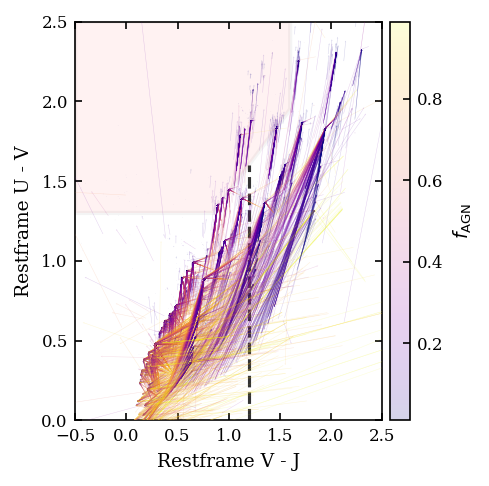

In [3]:
fig, ax = plt.subplots(figsize=visualization.PASA_SQ)
plot_uvj([], [], ax=ax, title="")
q = ax.quiver(d['VJ_Full'], d['UV_Full'], d['dvj'], d['duv'], d['fracAGN'],
              cmap='plasma', angles='xy', scale_units='xy', scale=1,
              width=0.0016, headwidth=3, headlength=3.5, headaxislength=3,
              alpha=0.18, zorder=3, rasterized=True)
cbar = fig.colorbar(q, ax=ax, pad=0.02)
cbar.set_label(FL)
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'UVJ_useall_allhosts_fracAGN_colored_combined.pdf'), dpi=300, bbox_inches='tight')
plt.show()

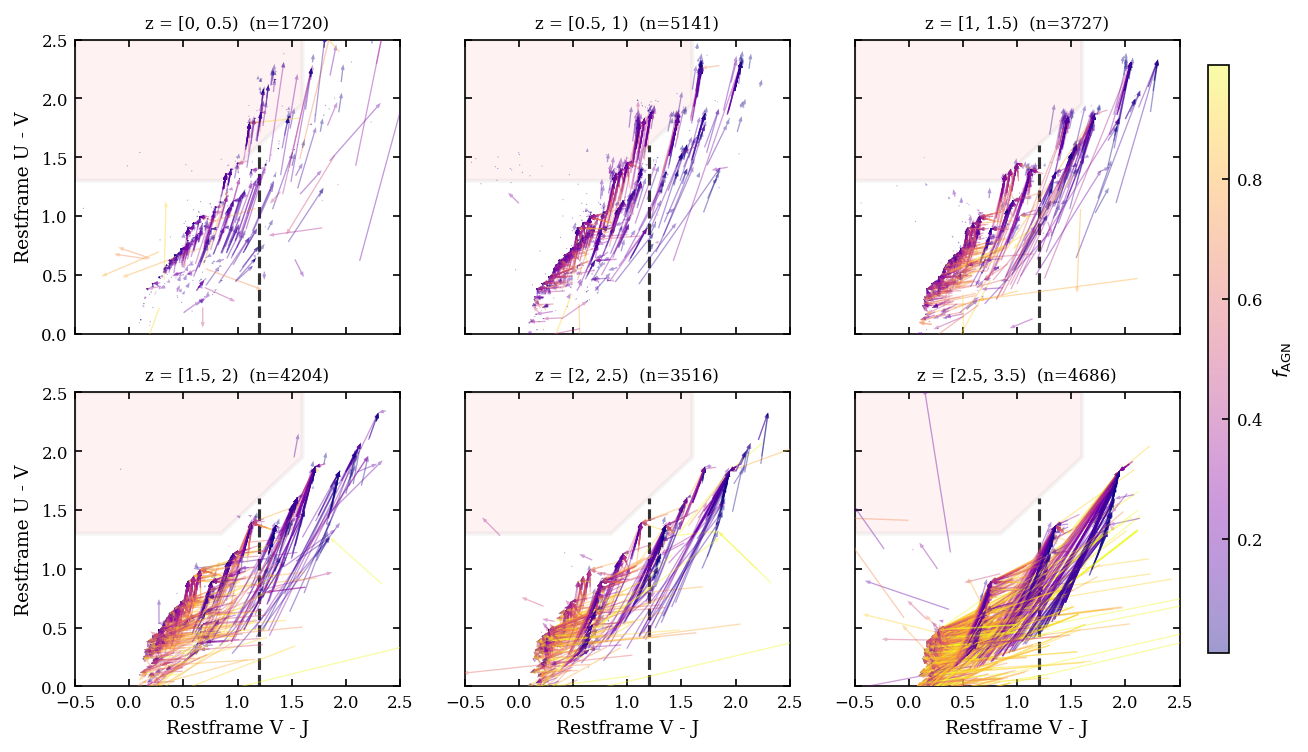

  z_bin  N_AGN_hosts  mean_fracAGN  mean_offset_mag
  0-0.5         1720         0.140            0.049
  0.5-1         5141         0.182            0.056
  1-1.5         3727         0.224            0.084
  1.5-2         4204         0.283            0.111
  2-2.5         3516         0.328            0.140
2.5-3.5         4686         0.429            0.267
AGN hosts above z=3.5 (not in the grid): 2237


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(9.5, 5.6), sharex=True, sharey=True)
norm = plt.Normalize(vmin=d['fracAGN'].min(), vmax=d['fracAGN'].max())
for ax, (zlo, zhi) in zip(axes.flat, z_bins):
    sub = d[(d[z_col] >= zlo) & (d[z_col] < zhi)]
    plot_uvj([], [], ax=ax, title="")
    q = ax.quiver(sub['VJ_Full'], sub['UV_Full'], sub['dvj'], sub['duv'], sub['fracAGN'],
                  cmap='plasma', norm=norm, angles='xy', scale_units='xy', scale=1,
                  width=0.004, headwidth=3, headlength=4, alpha=0.4, zorder=3, rasterized=True)
    ax.set_title(f'z = [{zlo}, {zhi})  (n={len(sub)})', fontsize=8)
for ax in axes[:-1, :].flat: ax.set_xlabel('')
for ax in axes[:, 1:].flat: ax.set_ylabel('')
fig.subplots_adjust(right=0.90)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
fig.colorbar(q, cax=cbar_ax, label=FL)
fig.savefig(os.path.join(OUT, 'UVJ_useall_allhosts_fracAGN_colored_redshift_bins.pdf'), dpi=300, bbox_inches='tight')
plt.show()

rows = []
for zlo, zhi in z_bins:
    s = d[(d[z_col] >= zlo) & (d[z_col] < zhi)]
    rows.append({'z_bin': f'{zlo}-{zhi}', 'N_AGN_hosts': len(s), 'mean_fracAGN': s['fracAGN'].mean(), 'mean_offset_mag': s['offset'].mean()})
zbin_table = pd.DataFrame(rows)
zbin_table.to_csv(os.path.join(OUT, 'useall_zbin_offset_table.csv'), index=False)
print(zbin_table.round(3).to_string(index=False))
print(f"AGN hosts above z=3.5 (not in the grid): {int((d[z_col] >= 3.5).sum())}")

## 3. Mean UVJ vector offset vs $f_{\rm AGN}$ (all hosts, $z<1.5$, $z\geq1.5$), with 95% bootstrap CIs

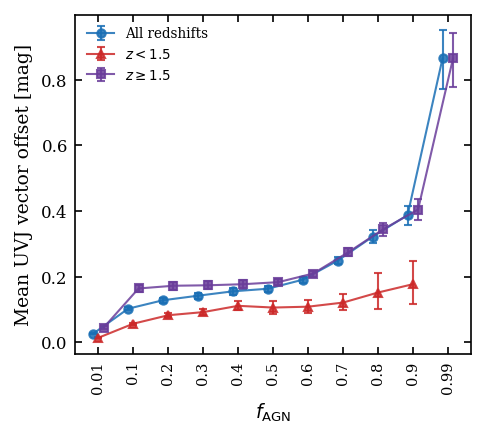

       sample  f_AGN    N  mean_offset  ci_lo  ci_hi
All redshifts   0.01 4224        0.026  0.025  0.028
All redshifts   0.10 5763        0.102  0.097  0.107
All redshifts   0.20 3873        0.128  0.121  0.135
All redshifts   0.30 2653        0.142  0.133  0.151
All redshifts   0.40 2071        0.155  0.146  0.166
All redshifts   0.50 1774        0.163  0.154  0.173
All redshifts   0.60 1602        0.191  0.182  0.200
All redshifts   0.70 1195        0.249  0.238  0.261
All redshifts   0.80 1001        0.322  0.303  0.341
All redshifts   0.90  779        0.388  0.357  0.417
All redshifts   0.99  296        0.864  0.772  0.951
    $z < 1.5$   0.01 2525        0.014  0.013  0.015
    $z < 1.5$   0.10 3312        0.057  0.054  0.060
    $z < 1.5$   0.20 1905        0.083  0.077  0.089
    $z < 1.5$   0.30 1032        0.092  0.083  0.102
    $z < 1.5$   0.40  683        0.111  0.099  0.125
    $z < 1.5$   0.50  460        0.106  0.088  0.125
    $z < 1.5$   0.60  299        0.109  0.091 

In [5]:
def pooled(data, col):
    grid = sorted(data['fracAGN'].unique())
    mean, lo, hi, n = [], [], [], []
    for fv in grid:
        v = data.loc[data['fracAGN'] == fv, col].dropna().values
        n.append(len(v)); mean.append(v.mean())
        b = rng.choice(v, size=(N_BOOT, len(v)), replace=True).mean(axis=1)
        lo.append(np.percentile(b, 2.5)); hi.append(np.percentile(b, 97.5))
    return grid, np.array(mean), np.array(lo), np.array(hi), np.array(n)

series = [
    ('All redshifts', d, '#1A6FB5', 'o', -0.15),
    (r'$z < 1.5$', d[d[z_col] < 1.5], '#CC2929', '^', 0.0),
    (r'$z \geq 1.5$', d[d[z_col] >= 1.5], '#6A3D9A', 's', 0.15),
]
fig, ax = plt.subplots(figsize=(3.31, 3.0))
off_tables = []
for label, data, color, marker, dx in series:
    g, m, lo, hi, n = pooled(data, 'offset')
    pos = np.array([FRAC_GRID.index(v) for v in g]) + dx
    ax.errorbar(pos, m, yerr=[m - lo, hi - m], fmt=marker + '-', color=color, ecolor=color,
                elinewidth=1, capsize=2, ms=4, lw=1, label=label, alpha=0.85)
    off_tables.append(pd.DataFrame({'sample': label, 'f_AGN': g, 'N': n, 'mean_offset': m, 'ci_lo': lo, 'ci_hi': hi}))
ax.set_xticks(np.arange(len(FRAC_GRID)))
ax.set_xticklabels([f'{v:g}' for v in FRAC_GRID], rotation=90, fontsize=7)
ax.set_xlabel(FL)
ax.set_ylabel('Mean UVJ vector offset [mag]')
ax.legend(fontsize=6.5, loc='upper left', frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'Paper_UVJ_Offset_vs_fAGN_useall.pdf'), bbox_inches='tight')
plt.show()
off_table = pd.concat(off_tables)
off_table.to_csv(os.path.join(OUT, 'useall_offset_vs_fAGN.csv'), index=False)
print(off_table.round(3).to_string(index=False))

## 3c. Signed UVJ offsets: which way does removing the AGN move the colours?

Sign convention: shift = (host-only colour) $-$ (full colour), i.e. the movement on removing the AGN. A positive $\Delta(U-V)$ is a redder $U-V$; a negative $\Delta(V-J)$ is a bluer $V-J$. The theoretical curves are the same quantity for the simple SED model: shift = (host galaxy template colour) $-$ (AGN composite colour), averaged over the 129 templates, for the Type 1 ($i=30^\circ$) and Type 2 ($i=70^\circ$) AGN.

In [6]:
from glass import data_io, composite_math
from src import config as _cfg
_filters = photometry.load_passbands(_cfg.FILTER_PATHS)
_agn = {'Type 1 theory': data_io.read_skirtor_model(_cfg.SKIRTOR_DIR, **_cfg.SKIRTOR_TYPE1_PARAMS),
        'Type 2 theory': data_io.read_skirtor_model(_cfg.SKIRTOR_DIR, **_cfg.SKIRTOR_TYPE2_PARAMS)}
_tmpl, _names = data_io.read_brown_galaxy_templates(_cfg.GALSEDATLAS_DIR)
_rows = []
for t_idx, gal in enumerate(_tmpl):
    for tname, model in _agn.items():
        for f in FRAC_GRID:
            comp = composite_math.create_composite_sed(model, gal, f / (1 - f))
            uv, vj = photometry.calculate_UVJ_colours(comp, _filters['U'], _filters['V'], _filters['J'])
            _rows.append({'type': tname, 'template': t_idx, 'f_AGN': f, 'UV': uv, 'VJ': vj})
_th = pd.DataFrame(_rows)
_th0 = _th[_th.f_AGN == FRAC_GRID[0]]   # lowest f_AGN on the grid (0.01); the f=0 host is added below
_zero = []
for t_idx, gal in enumerate(_tmpl):
    uv, vj = photometry.calculate_UVJ_colours(gal, _filters['U'], _filters['V'], _filters['J'])
    _zero.append({'template': t_idx, 'UV0': uv, 'VJ0': vj})
_th = _th.merge(pd.DataFrame(_zero), on='template')
_th['dUV'] = _th['UV0'] - _th['UV']          # host minus composite = shift on removing the AGN
_th['dVJ'] = _th['VJ0'] - _th['VJ']
theory_signed = _th.groupby(['type', 'f_AGN'])[['dUV', 'dVJ']].mean().reset_index()
print(theory_signed.pivot(index='f_AGN', columns='type', values='dUV').round(3).T.to_string())

f_AGN          0.01   0.10   0.20   0.30   0.40   0.50   0.60   0.70   0.80   0.90   0.99
type                                                                                     
Type 1 theory  0.01  0.097  0.193  0.292  0.396  0.508  0.631  0.769  0.928  1.119  1.335
Type 2 theory  0.00  0.000  0.000  0.000  0.001  0.001  0.002  0.003  0.004  0.010  0.088


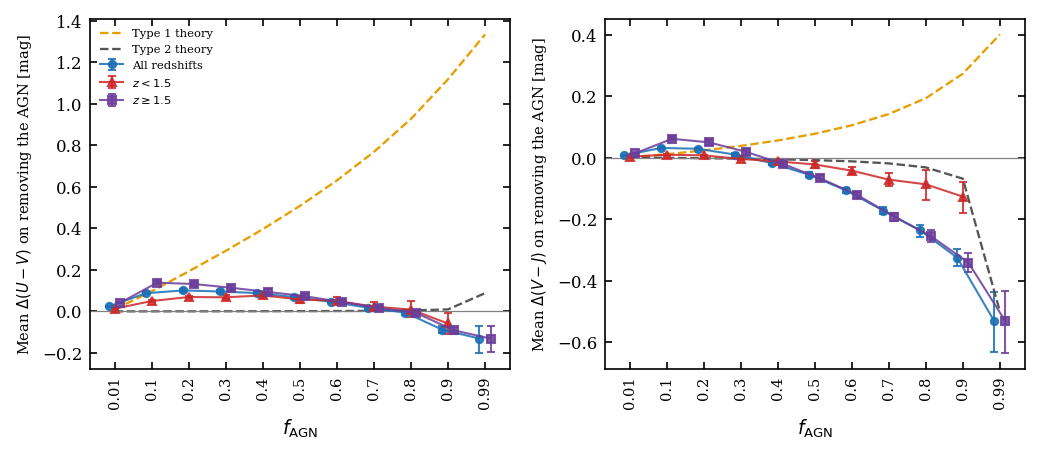

observed mean signed offsets (all redshifts):
component    duv    dvj
f_AGN                  
0.01       0.024  0.007
0.10       0.088  0.031
0.20       0.101  0.029
0.30       0.096  0.010
0.40       0.088 -0.018
0.50       0.069 -0.056
0.60       0.046 -0.107
0.70       0.018 -0.172
0.80      -0.006 -0.237
0.90      -0.088 -0.326
0.99      -0.131 -0.532

share of galaxies moving in the "typical" direction:
f_AGN            0.01  0.10  0.20  0.30  0.40  0.50  0.60  0.70  0.80  0.90  0.99
frac with dUV>0  0.79  0.79  0.77  0.74  0.70  0.66  0.59  0.51  0.40  0.20  0.18
frac with dVJ<0  0.44  0.51  0.57  0.68  0.76  0.85  0.91  0.94  0.95  0.98  0.87


In [7]:
series = [('All redshifts', d, '#1A6FB5', 'o', -0.15), (r'$z<1.5$', d[d[z_col] < 1.5], '#CC2929', '^', 0.0), (r'$z\geq1.5$', d[d[z_col] >= 1.5], '#6A3D9A', 's', 0.15)]
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1))
rows = []
for ax, col, ylab in [(axes[0], 'duv', r'Mean $\Delta(U-V)$ on removing the AGN [mag]'), (axes[1], 'dvj', r'Mean $\Delta(V-J)$ on removing the AGN [mag]')]:
    for label, data, color, marker, dx in series:
        gg, m, lo_, hi_, n = pooled(data, col)
        pos = np.array([FRAC_GRID.index(v) for v in gg]) + dx
        ax.errorbar(pos, m, yerr=[m - lo_, hi_ - m], fmt=marker + '-', color=color, ecolor=color, elinewidth=1, capsize=2, ms=3.5, lw=1, label=label, alpha=0.85)
        rows.append(pd.DataFrame({'component': col, 'sample': label, 'f_AGN': gg, 'N': n, 'mean': m, 'ci_lo': lo_, 'ci_hi': hi_}))
    for tname, ls_, c_ in [('Type 1 theory', '--', '#E69F00'), ('Type 2 theory', '--', '#555555')]:
        th = theory_signed[theory_signed.type == tname].sort_values('f_AGN')
        ax.plot([FRAC_GRID.index(v) for v in th.f_AGN], th['dUV' if col == 'duv' else 'dVJ'], ls_, color=c_, lw=1.1, label=tname)
    ax.axhline(0, color='grey', lw=0.6)
    ax.set_xticks(np.arange(len(FRAC_GRID))); ax.set_xticklabels([f'{v:g}' for v in FRAC_GRID], rotation=90, fontsize=7)
    ax.set_xlabel(FL); ax.set_ylabel(ylab, fontsize=7)
axes[0].legend(fontsize=5.5, frameon=False, loc='upper left')
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'UVJ_useall_signed_offsets_vs_fAGN.pdf'), bbox_inches='tight')
plt.show()
signed = pd.concat(rows); signed.to_csv(os.path.join(OUT, 'useall_signed_offsets_vs_fAGN.csv'), index=False)
pt = signed[signed['sample'] == 'All redshifts'].pivot(index='f_AGN', columns='component', values='mean').round(3)
share = pd.DataFrame({'f_AGN': FRAC_GRID})
for col, nm in [('duv', 'frac with dUV>0'), ('dvj', 'frac with dVJ<0')]:
    share[nm] = [round(float((d.loc[d.fracAGN == f, col] > 0).mean() if col == 'duv' else (d.loc[d.fracAGN == f, col] < 0).mean()), 2) for f in FRAC_GRID]
print('observed mean signed offsets (all redshifts):'); print(pt.to_string())
print('\nshare of galaxies moving in the "typical" direction:'); print(share.set_index('f_AGN').T.to_string())

## 3b. Theory vs decomposition: mean UVJ vector offset vs $f_{m AGN}$

Theoretical Type 1 ($i=30^\circ$) and Type 2 ($i=70^\circ$) composites (129 GALSEDATLAS templates, current `glass` and `config`) against the observed offsets from the decomposition (all redshifts).

Type 1 ($i=30^\circ$) [0.01  0.1   0.2   0.303 0.412 0.53  0.661 0.809 0.982 1.197 1.456]
Type 2 ($i=70^\circ$) [0.    0.001 0.002 0.004 0.006 0.008 0.013 0.019 0.033 0.07  0.515]


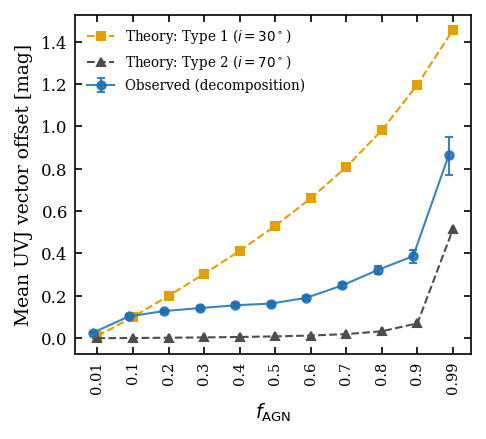

In [8]:
from glass import data_io, composite_math, analysis
filters = photometry.load_passbands(config.FILTER_PATHS)
agn_models = {
    'Type 1 ($i=30^\circ$)': data_io.read_skirtor_model(config.SKIRTOR_DIR, **config.SKIRTOR_TYPE1_PARAMS),
    'Type 2 ($i=70^\circ$)': data_io.read_skirtor_model(config.SKIRTOR_DIR, **config.SKIRTOR_TYPE2_PARAMS),
}
gal_templates, gal_names = data_io.read_brown_galaxy_templates(config.GALSEDATLAS_DIR)
TH_FRAC = np.array([0.0] + [float(v) for v in FRAC_GRID])
th_rows = []
for t, gal in enumerate(gal_templates):
    for tname, model in agn_models.items():
        for f in TH_FRAC:
            comp = composite_math.create_composite_sed(model, gal, f / (1 - f))
            uv, vj = photometry.calculate_UVJ_colours(comp, filters['U'], filters['V'], filters['J'])
            th_rows.append({'type': tname, 'f_AGN': f, 'UV': uv, 'VJ': vj})
th = pd.DataFrame(th_rows)
theory_off = {}
for tname in agn_models:
    sub = th[th['type'] == tname]; init = sub[sub['f_AGN'] == 0.0]
    theory_off[tname] = [analysis.calculate_mean_vector_offset(sub[sub['f_AGN'] == f]['VJ'].values, sub[sub['f_AGN'] == f]['UV'].values,
                                                              init['VJ'].values, init['UV'].values) for f in FRAC_GRID]
    print(tname, np.round(theory_off[tname], 3))

obs = off_table[off_table['sample'] == 'All redshifts']
pos = np.arange(len(FRAC_GRID))
fig, ax = plt.subplots(figsize=(3.31, 3.0))
ax.errorbar(pos - 0.12, obs['mean_offset'], yerr=[obs['mean_offset'] - obs['ci_lo'], obs['ci_hi'] - obs['mean_offset']],
            fmt='o-', color='#1A6FB5', ecolor='#1A6FB5', elinewidth=1, capsize=2, ms=4, lw=1, alpha=0.85, label='Observed (decomposition)')
ax.plot(pos, theory_off['Type 1 ($i=30^\circ$)'], 's--', color='#E69F00', ms=3.5, lw=1, label=r'Theory: Type 1 ($i=30^\circ$)')
ax.plot(pos, theory_off['Type 2 ($i=70^\circ$)'], '^--', color='#4D4D4D', ms=3.5, lw=1, label=r'Theory: Type 2 ($i=70^\circ$)')
ax.set_xticks(pos)
ax.set_xticklabels([f'{v:g}' for v in FRAC_GRID], rotation=90, fontsize=7)
ax.set_xlabel(FL)
ax.set_ylabel('Mean UVJ vector offset [mag]')
ax.legend(fontsize=6.5, loc='upper left', frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'Paper_UVJ_offset_theory_vs_observed_useall.pdf'), bbox_inches='tight')
plt.show()
pd.DataFrame({'f_AGN': FRAC_GRID, 'theory_type1': theory_off['Type 1 ($i=30^\circ$)'], 'theory_type2': theory_off['Type 2 ($i=70^\circ$)'],
              'observed': obs['mean_offset'].values}).to_csv(os.path.join(OUT, 'useall_offset_theory_vs_observed.csv'), index=False)


## 4. Fraction migrating to quiescent vs $f_{\rm AGN}$ (all redshifts vs $z<1.5$)

Among AGN hosts that are not quiescent in full photometry ('at risk'), the fraction that are quiescent once the CIGALE AGN is removed.

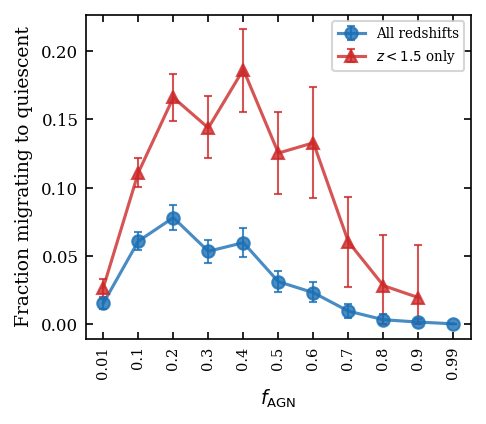

        sample  f_AGN  N_at_risk  migration_rate  ci_lo  ci_hi
 All redshifts   0.01       3928          0.0150 0.0112 0.0186
 All redshifts   0.10       5408          0.0607 0.0545 0.0671
 All redshifts   0.20       3696          0.0779 0.0690 0.0869
 All redshifts   0.30       2574          0.0532 0.0447 0.0618
 All redshifts   0.40       2031          0.0596 0.0492 0.0704
 All redshifts   0.50       1745          0.0309 0.0235 0.0390
 All redshifts   0.60       1574          0.0229 0.0159 0.0305
 All redshifts   0.70       1179          0.0093 0.0042 0.0144
 All redshifts   0.80        992          0.0030 0.0000 0.0071
 All redshifts   0.90        773          0.0013 0.0000 0.0039
 All redshifts   0.99        296          0.0000 0.0000 0.0000
$z < 1.5$ only   0.01       2230          0.0265 0.0197 0.0332
$z < 1.5$ only   0.10       2958          0.1109 0.1001 0.1221
$z < 1.5$ only   0.20       1728          0.1661 0.1487 0.1834
$z < 1.5$ only   0.30        953          0.1438 0.1217

In [9]:
risk = d[d['cls_full'] != 0].copy()
risk['moved'] = (risk['cls_dec'] == 0).astype(float)

def migration(data):
    g, m, lo, hi, n = pooled(data, 'moved')
    return g, m, lo, hi, n

fig, ax = plt.subplots(figsize=(3.31, 2.9))
mig_tables = []
for label, data, color, marker, dx in [('All redshifts', risk, '#1A6FB5', 'o', 0.0), (r'$z < 1.5$ only', risk[risk[z_col] < 1.5], '#CC2929', '^', 0.0)]:
    g, m, lo, hi, n = migration(data)
    pos = np.array([FRAC_GRID.index(v) for v in g])
    ax.errorbar(pos, m, yerr=[m - lo, hi - m], fmt=marker + '-', color=color, ecolor=color, elinewidth=1, capsize=2,
                label=label, alpha=0.8)
    mig_tables.append(pd.DataFrame({'sample': label, 'f_AGN': g, 'N_at_risk': n, 'migration_rate': m, 'ci_lo': lo, 'ci_hi': hi}))
ax.set_xticks(np.arange(len(FRAC_GRID)))
ax.set_xticklabels([f'{v:g}' for v in FRAC_GRID], rotation=90, fontsize=7)
ax.set_xlabel(FL)
ax.set_ylabel('Fraction migrating to quiescent')
ax.legend(fontsize=6.5, loc='upper right')
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'UVJ_useall_fracAGN_redshift_confound.pdf'), dpi=300, bbox_inches='tight')
plt.show()
mig_table = pd.concat(mig_tables)
mig_table.to_csv(os.path.join(OUT, 'useall_migration_vs_fAGN.csv'), index=False)
print(mig_table.round(4).to_string(index=False))

print('\nmigrators by redshift bin (AGN hosts):')
for zlo, zhi in z_bins:
    s = d[(d[z_col] >= zlo) & (d[z_col] < zhi)]
    print(f"  z={zlo}-{zhi}: AGN hosts {len(s):5d}  quiescent in full {int((s.cls_full == 0).sum()):4d}  quiescent in host-only {int((s.cls_dec == 0).sum()):4d}  migrators {int(s.mover.sum()):4d}")

## 5. AGN luminosity vs redshift (do low-luminosity AGN exist at $z\geq1.5$?)

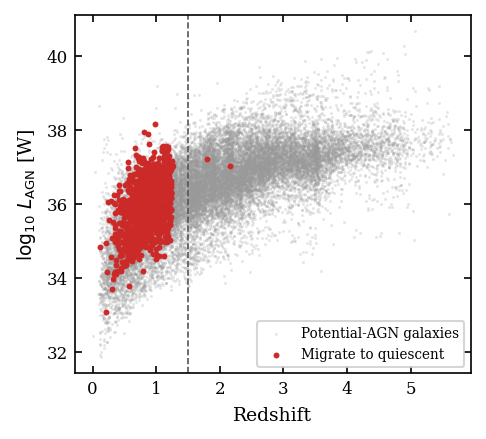

z=[0,1.5): n=10588, logL 5/50/95 pct = [33.88 35.62 36.99]
z=[1.5,7): n=14643, logL 5/50/95 pct = [35.68 37.   38.11]
migrators logL 5/50/95 pct = [34.77 36.01 37.03]


In [10]:
dl = d[d['L_AGN'] > 0].copy()
dl['logL'] = np.log10(dl['L_AGN'])
fig, ax = plt.subplots(figsize=(3.31, 3.0))
ax.scatter(dl[z_col], dl['logL'], s=2, c='#999999', alpha=0.25, lw=0, label='Potential-AGN galaxies', rasterized=True)
mv = dl[dl['mover']]
ax.scatter(mv[z_col], mv['logL'], s=8, c='#CC2929', lw=0, label='Migrate to quiescent')
ax.axvline(1.5, color='#555555', ls='--', lw=0.8)
ax.set_xlabel('Redshift')
ax.set_ylabel(r'$\log_{10}\,L_{\rm AGN}$ [W]')
ax.legend(fontsize=6.5, loc='lower right')
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'UVJ_useall_LAGN_vs_redshift.pdf'), dpi=300, bbox_inches='tight')
plt.show()
for lo_z, hi_z in [(0, 1.5), (1.5, 7)]:
    s = dl[(dl[z_col] >= lo_z) & (dl[z_col] < hi_z)]
    print(f"z=[{lo_z},{hi_z}): n={len(s)}, logL 5/50/95 pct = {np.percentile(s['logL'], [5, 50, 95]).round(2)}")
print('migrators logL 5/50/95 pct =', np.percentile(mv['logL'], [5, 50, 95]).round(2))

## 6. Closing the loop: re-adding a theoretical AGN to the host-only SED

Recombined colours come from `scripts/build_useall_recombination.py` (Type 1 template, Type 2 template, and CIGALE-matched geometry), with alpha = f_AGN / (1 - f_AGN) from the CIGALE fracAGN (not fitted).

In [11]:
rec = pd.read_csv(os.path.join(DATA, 'zfourge_useall_recombined.csv'))
h = d.merge(rec, on='ID', how='inner')
METHODS = ['Type1', 'Type2', 'Matched']
for m in METHODS:
    h[f'cls_rec_{m}'] = photometry.classify_uvj(h[f'VJ_rec_{m}'].fillna(0).values, h[f'UV_rec_{m}'].fillna(0).values)
    h.loc[h[f'UV_rec_{m}'].isna() | h[f'VJ_rec_{m}'].isna(), f'cls_rec_{m}'] = -1
print(f"AGN hosts with recombined colours: {len(h)} of {len(d)}")

def boot_mean(v, seed):
    v = np.asarray(v, dtype=float)
    b = np.random.default_rng(seed).choice(v, size=(N_BOOT, len(v)), replace=True).mean(axis=1)
    return v.mean(), *np.percentile(b, [2.5, 97.5])

print('\nOriginal UVJ class recovered after re-adding the AGN (point [95% CI]):')
stats_rows = []
for m in METHODS:
    ok = h[f'cls_rec_{m}'] != -1
    hit_all = (h.loc[ok, f'cls_rec_{m}'] == h.loc[ok, 'cls_full']).astype(float)
    mv_ = h[ok & h['mover']]
    hit_mv = (mv_[f'cls_rec_{m}'] == mv_['cls_full']).astype(float)
    a_ = boot_mean(hit_all, 1); b_ = boot_mean(hit_mv, 2)
    fp = int((ok & (h.cls_full != 0) & (h[f'cls_rec_{m}'] == 0)).sum()); fn = int((ok & (h.cls_full == 0) & (h[f'cls_rec_{m}'] != 0)).sum())
    nq = int((h.cls_full == 0).sum())
    print(f"  {m:8s} all hosts {a_[0]:.3f} [{a_[1]:.3f}, {a_[2]:.3f}] (n={int(ok.sum())}) | migrators {b_[0]:.3f} [{b_[1]:.3f}, {b_[2]:.3f}] (n={len(mv_)}) | false-pos Q {fp}, false-neg Q {fn} of {nq} true Q")
    stats_rows.append({'method': m, 'all_recovered': a_[0], 'all_lo': a_[1], 'all_hi': a_[2], 'n_all': int(ok.sum()),
                       'migrators_recovered': b_[0], 'mig_lo': b_[1], 'mig_hi': b_[2], 'n_migrators': len(mv_), 'false_pos_Q': fp, 'false_neg_Q': fn, 'n_true_Q': nq})
pd.DataFrame(stats_rows).to_csv(os.path.join(OUT, 'useall_recombination_class_recovery.csv'), index=False)
# 'Do nothing' baseline: class already equal between host-only and full photometry
base_all = float((h['cls_dec'] == h['cls_full']).mean())
print(f"\nBaseline (host-only class already equals full class): {base_all:.3f} of {len(h)} potential-AGN galaxies")
for m in METHODS:
    ok = h[f'cls_rec_{m}'] != -1
    print(f"  {m:8s} baseline on its own subset: {(h.loc[ok,'cls_dec'] == h.loc[ok,'cls_full']).mean():.3f} (n={int(ok.sum())})")
print(f"  migrating hosts baseline: {(h.loc[h['mover'],'cls_dec'] == h.loc[h['mover'],'cls_full']).mean():.3f}")


AGN hosts with recombined colours: 25231 of 25231

Original UVJ class recovered after re-adding the AGN (point [95% CI]):


  Type1    all hosts 0.953 [0.951, 0.956] (n=25048) | migrators 0.980 [0.971, 0.988] (n=1038) | false-pos Q 18, false-neg Q 374 of 1035 true Q


  Type2    all hosts 0.929 [0.926, 0.932] (n=25163) | migrators 0.015 [0.009, 0.023] (n=1038) | false-pos Q 1021, false-neg Q 8 of 1035 true Q


  Matched  all hosts 0.963 [0.961, 0.965] (n=25046) | migrators 0.981 [0.973, 0.988] (n=1038) | false-pos Q 18, false-neg Q 132 of 1035 true Q

Baseline (host-only class already equals full class): 0.930 of 25231 potential-AGN galaxies
  Type1    baseline on its own subset: 0.931 (n=25048)
  Type2    baseline on its own subset: 0.931 (n=25163)
  Matched  baseline on its own subset: 0.931 (n=25046)
  migrating hosts baseline: 0.000


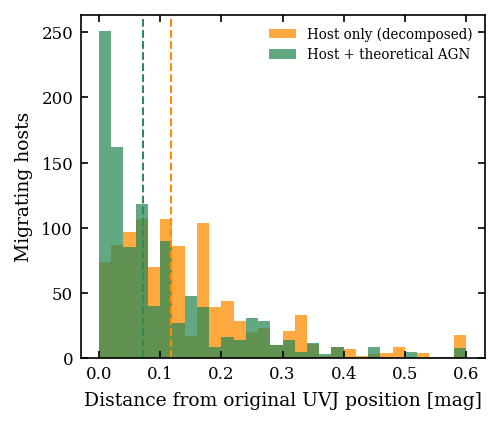

n = 1038 migrating hosts; median distance from original position: host-only 0.118 mag -> with AGN added back 0.071 mag
fraction closer to the original after adding the AGN back: 70.9%


In [12]:
mv = h[h['mover'] & (h['cls_rec_Matched'] != -1)].copy()
mv['d_host'] = np.hypot(mv['VJ_Decomposed'] - mv['VJ_Full'], mv['UV_Decomposed'] - mv['UV_Full'])
mv['d_back'] = np.hypot(mv['VJ_rec_Matched'] - mv['VJ_Full'], mv['UV_rec_Matched'] - mv['UV_Full'])

fig, ax = plt.subplots(figsize=(3.4, 2.9))
edges = np.linspace(0, 0.6, 31)
ax.hist(mv['d_host'].clip(upper=0.6), bins=edges, color='darkorange', alpha=0.75, label='Host only (decomposed)')
ax.hist(mv['d_back'].clip(upper=0.6), bins=edges, color='#2E8B57', alpha=0.75, label='Host + theoretical AGN')
for col, c_ in [('d_host', 'darkorange'), ('d_back', '#2E8B57')]:
    ax.axvline(mv[col].median(), color=c_, ls='--', lw=1)
ax.set_xlabel('Distance from original UVJ position [mag]')
ax.set_ylabel('Migrating hosts')
ax.legend(fontsize=6.5, frameon=False)
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'UVJ_useall_recombination_validation.pdf'), bbox_inches='tight')
plt.show()
print(f"n = {len(mv)} migrating hosts; median distance from original position: host-only {mv['d_host'].median():.3f} mag -> with AGN added back {mv['d_back'].median():.3f} mag")
print(f"fraction closer to the original after adding the AGN back: {(mv['d_back'] < mv['d_host']).mean():.1%}")

## 7. Demographics of the migrating hosts vs the rest ($z\leq1.5$)

Migrating hosts (star-forming or dusty in full photometry, quiescent once decomposed), non-migrating AGN hosts, and the full $z\leq1.5$ `Use==1` parent population.

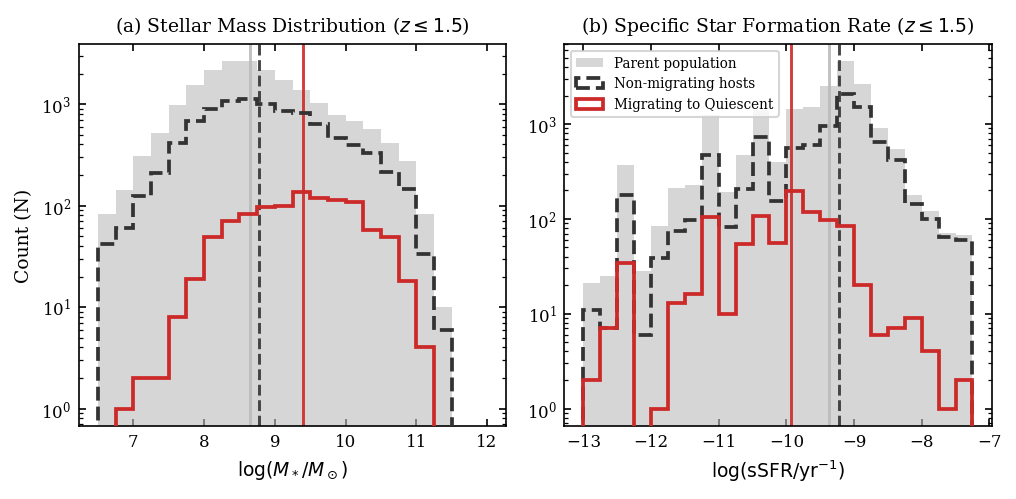

                 group     n  median_lmass  median_lssfr
     Parent population 20207          8.65         -9.37
   Non-migrating hosts  9553          8.78         -9.22
Migrating to Quiescent  1036          9.40         -9.93


In [13]:
mbins = np.arange(6.5, 12.01, 0.25)
sbins = np.arange(-13.0, -7.01, 0.25)
dz = d[d[z_col] <= 1.5]
migrating = dz[dz['mover']]
non_migrating = dz[~dz['mover']]
parent_z = tab[tab[z_col] <= 1.5]
groups_z = [('Parent population', parent_z, '#BBBBBB', None),
            ('Non-migrating hosts', non_migrating, '#333333', '--'),
            ('Migrating to Quiescent', migrating, '#CC2929', '-')]

fig, axes = plt.subplots(1, 2, figsize=(6.85, 3.4))
panels_z = [(axes[0], 'lmass', mbins, r'$\log(M_*/M_\odot)$', r'(a) Stellar Mass Distribution ($z \leq 1.5$)'),
            (axes[1], 'lssfr', sbins, r'$\log(\mathrm{sSFR}/\mathrm{yr}^{-1})$', r'(b) Specific Star Formation Rate ($z \leq 1.5$)')]
for ax, col, bins, xlabel, title in panels_z:
    for gname, gdf, color, ls in groups_z:
        vals = gdf[col].dropna()
        if ls is None:
            ax.hist(vals, bins=bins, color=color, alpha=0.6, label=gname, zorder=2)
        else:
            ax.hist(vals, bins=bins, histtype='step', color=color, lw=1.8, linestyle=ls, label=gname, zorder=3)
        ax.axvline(vals.median(), color=color, lw=1.4, linestyle=ls or '-', alpha=0.9)
    ax.set_yscale('log')
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=9)
axes[0].set_ylabel('Count (N)')
axes[1].legend(fontsize=6.5, loc='upper left')
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'UVJ_useall_movers_vs_population.pdf'), dpi=300, bbox_inches='tight')
plt.show()
demo = pd.DataFrame([{'group': g, 'n': len(df_), 'median_lmass': df_['lmass'].median(), 'median_lssfr': df_['lssfr'].median()} for g, df_, _, _ in groups_z])
demo.to_csv(os.path.join(OUT, 'useall_movers_demographics.csv'), index=False)
print(demo.round(2).to_string(index=False))

## 7b. Quiescent fraction of all galaxies: full vs host-only photometry

In [14]:
zsel = [('z<0.5', tab[z_col] < 0.5), ('0.5<=z<1', (tab[z_col] >= 0.5) & (tab[z_col] < 1)), ('1<=z<1.5', (tab[z_col] >= 1) & (tab[z_col] < 1.5)),
        ('z<=1.5', tab[z_col] <= 1.5), ('all z', tab[z_col] > -99)]
qrows = []
for name, m_ in zsel:
    s = tab[m_]; n_ = len(s); qf = int((s['cls_full'] == 0).sum()); qd = int((s['cls_dec'] == 0).sum())
    qrows.append({'sample': name, 'N': n_, 'Q_full': qf, 'Q_host_only': qd, 'frac_full': qf / n_, 'frac_host_only': qd / n_,
                  'delta_pp': 100 * (qd - qf) / n_, 'N_become_Q': int(((s['cls_full'] != 0) & (s['cls_dec'] == 0)).sum()),
                  'N_leave_Q': int(((s['cls_full'] == 0) & (s['cls_dec'] != 0)).sum())})
qtab = pd.DataFrame(qrows)
qtab.to_csv(os.path.join(OUT, 'useall_quiescent_fraction_full_vs_host.csv'), index=False)
print(qtab.round(4).to_string(index=False))


  sample     N  Q_full  Q_host_only  frac_full  frac_host_only  delta_pp  N_become_Q  N_leave_Q
   z<0.5  3979     712          784     0.1789          0.1970    1.8095          72          0
0.5<=z<1  9770    1209         1870     0.1237          0.1914    6.7656         661          0
1<=z<1.5  6456     132          435     0.0204          0.0674    4.6933         303          0
  z<=1.5 20207    2053         3089     0.1016          0.1529    5.1269        1036          0
   all z 37541    2057         3094     0.0548          0.0824    2.7623        1038          1


## 8. Summary numbers for the paper text

In [15]:
summary = {
    'N_Use1': n_all, 'N_with_colours': len(tab), 'N_AGN_hosts': len(d), 'N_migrators': int(d['mover'].sum()),
    'N_leaving_quiescent': int(((d['cls_full'] == 0) & (d['cls_dec'] != 0)).sum()),
    'median_z_all': tab[z_col].median(), 'median_z_AGN': d[z_col].median(),
    'N_migrators_z_le_1p5': int(dz['mover'].sum()), 'N_migrators_z_gt_1p5': int(d[d[z_col] > 1.5]['mover'].sum()),
    'N_quiescent_full_z_ge_1p5': int(((tab[z_col] >= 1.5) & (tab['cls_full'] == 0)).sum()),
}
pd.Series(summary).to_csv(os.path.join(OUT, 'useall_summary_numbers.csv'), header=['value'])
print(pd.Series(summary).to_string())

N_Use1                       37647.0000
N_with_colours               37541.0000
N_AGN_hosts                  25231.0000
N_migrators                   1038.0000
N_leaving_quiescent              1.0000
median_z_all                     1.3691
median_z_AGN                     1.7348
N_migrators_z_le_1p5          1036.0000
N_migrators_z_gt_1p5             2.0000
N_quiescent_full_z_ge_1p5        4.0000
